In [56]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from statsmodels.stats.proportion import proportions_ztest

In [57]:
df = pd.read_csv('Cleaned Survey Data.csv')

In [58]:
n=len(df)
n

40

In [59]:
# OBJECTIVE 1: CONSUMPTION SHIFT (Z-TEST)
# Success Count: Number of people who spent 3+ hours (value 3.5 or higher)
# Group 1 is 'Post Covid', Group 2 is 'Pre Covid'
count = [len(df[df['Post Covid Hours'] >= 3.5]), len(df[df['Pre Covid Hours'] >= 3.5])]

# Observations: The total sample size for both groups (40 and 40)
nobs = [n, n]

# Running the Z-test to see if the jump in usage is statistically significant
z_score, p_value_obj1 = proportions_ztest(count, nobs, alternative='larger')
print(f"Objective 1 - Consumption Shift P-Value: {p_value_obj1:.5f}")

Objective 1 - Consumption Shift P-Value: 0.00005


In [60]:
# OBJECTIVE 2: PERCEIVED UTILITY & SOCIAL DISCOMFORT
# Z-Test for Social Discomfort (Comparing High Comfort 4-5 vs Low Comfort 1-2)
comfort_col = 'On a scale of 1 to 5, rate your comfort level with respect to real time interaction after virtual interaction throughout lockdown'

# Group 1 is Ratings 4 & 5, Group 2 is 1 and 2
count_comfort = [len(df[df[comfort_col] >= 4]), len(df[df[comfort_col] <= 2])]

# Running the Z-test to see if the difference in social discomfort zones is statistically significant
z_comfort, p_value_obj2 = proportions_ztest(count_comfort, nobs)
print(f"Objective 2 - Social Comfort P-Value: {p_value_obj2:.4f}")

Objective 2 - Social Comfort P-Value: 0.1035


In [61]:
# OBJECTIVE 3: MISINFORMATION VULNERABILITY
# Calculating the percentage of people who believed fake news
# Since 'Believed Fake News' is 1 for Yes and 0 for No, the mean * 100 gives the %
misinfo_rate = df['Believed Fake News'].mean() * 100
print(f"Objective 3 - Misinformation Vulnerability Rate: {misinfo_rate:.1f}%")

Objective 3 - Misinformation Vulnerability Rate: 60.0%


In [62]:
# OBJECTIVE 4: MENTAL HEALTH IMPACT (Z-TEST)
# Defining the column name for mental health impact
mh_col = 'On a scale of 1 to 5, rate how significant was the impact of online media on your mental health during the pandemic'

# Success Count: Comparing High Impact (4-5) against Low Impact (1-2)
count_mh = [len(df[df[mh_col] >= 4]), len(df[df[mh_col] <= 2])]

# Running the Z-test to see if high impact is significantly more common than low impact
z_score_mh, p_value_obj4 = proportions_ztest(count_mh, nobs, alternative='larger')
print(f"Objective 4 P-Value: {p_value_obj4:.5f}")

Objective 4 P-Value: 0.00209


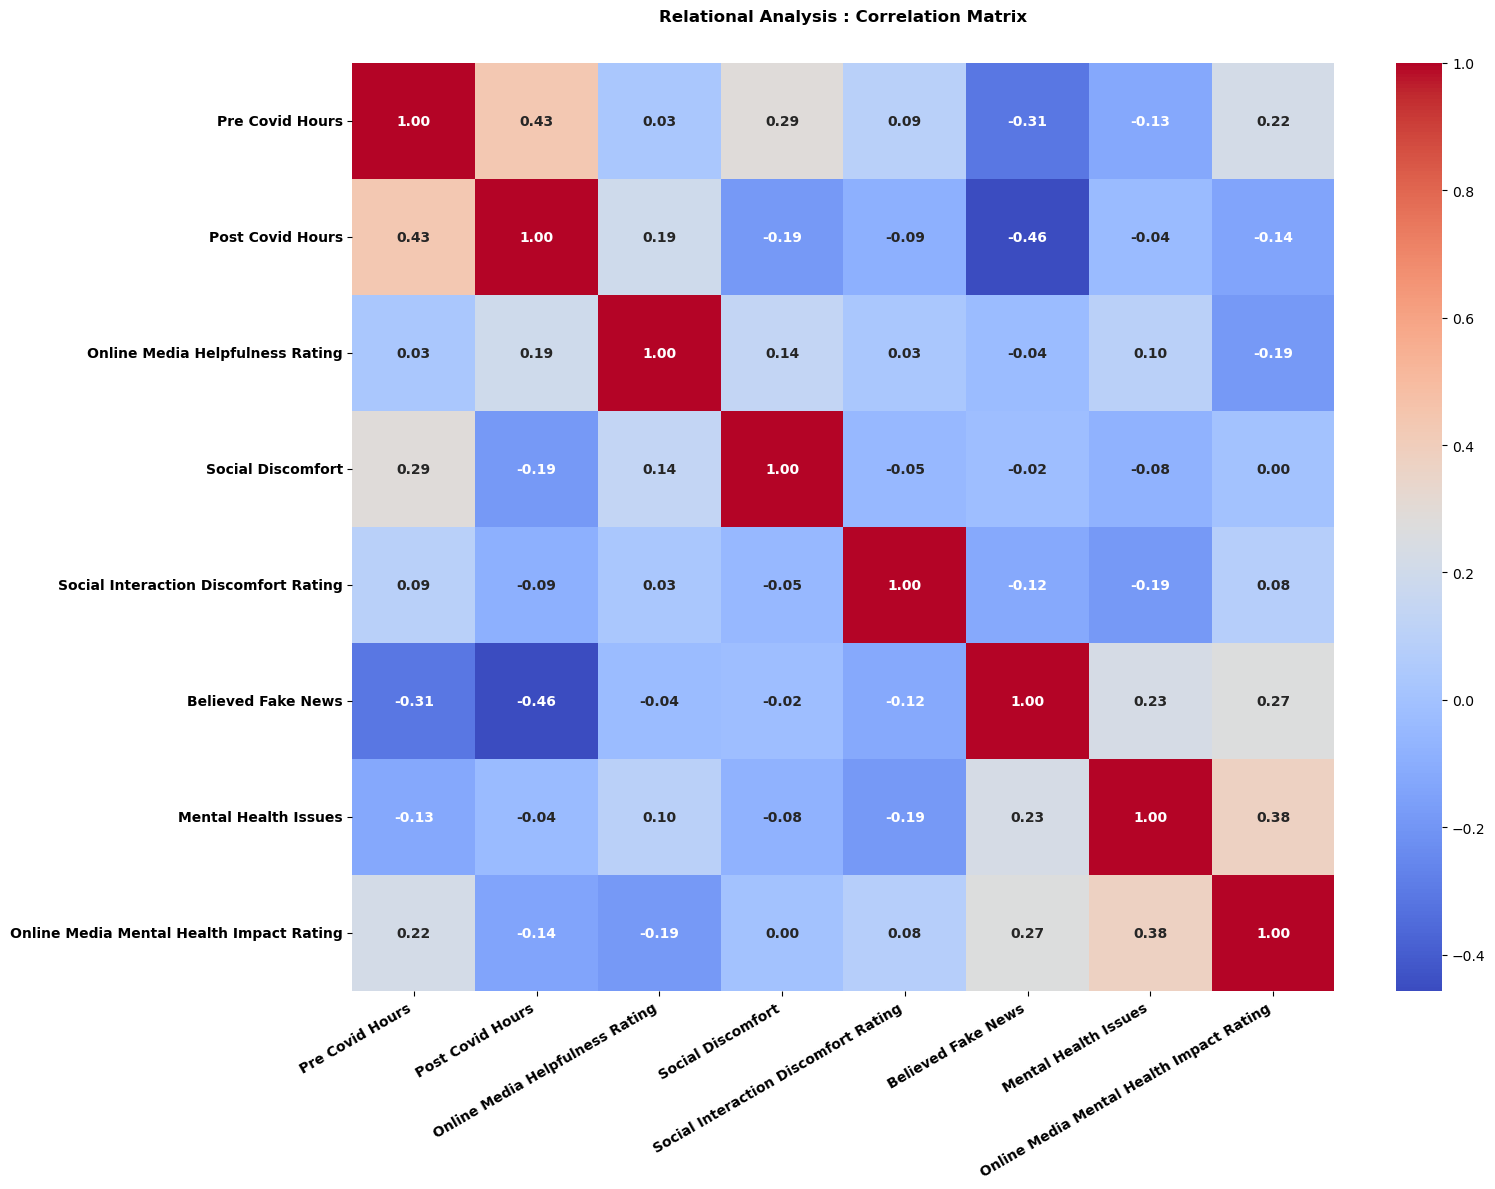

In [55]:
# OBJECTIVE 5: CORRELATION HEATMAP (RELATIONAL ANALYSIS)
# Listing only the specific columns we want to see in the heatmap
cols = [
    'Pre Covid Hours', 
    'Post Covid Hours', 
    'On a scale of 1 to 5, rate the level of helpfulness of online media during the pandemic',
    'Social Discomfort', 
    'On a scale of 1 to 5, rate your comfort level with respect to real time interaction after virtual interaction throughout lockdown',
    'Believed Fake News', 
    'Mental Health Issues', 
    'On a scale of 1 to 5, rate how significant was the impact of online media on your mental health during the pandemic'
]

graph_labels = [
    'Pre Covid Hours',
    'Post Covid Hours',
    'Online Media Helpfulness Rating',
    'Social Discomfort',
    'Social Interaction Discomfort Rating',
    'Believed Fake News',
    'Mental Health Issues',
    'Online Media Mental Health Impact Rating'
]

# Setting the size of the plot
plt.figure(figsize=(16, 12))

# Generating the heatmap using Pearson correlation (.corr())
# annot=True shows the numbers, cmap='coolwarm' sets the blue-to-red color scale
sns.heatmap(df[cols].corr(), annot=True, cmap='coolwarm', fmt=".2f", annot_kws={"weight": "bold"}, xticklabels=graph_labels, yticklabels=graph_labels)

# Adding a title to the plot
plt.title('Relational Analysis : Correlation Matrix', fontweight='bold', pad=30)

plt.xticks(fontweight='bold', rotation=30, ha='right')
plt.yticks(fontweight='bold')

plt.tight_layout()

# Displaying the plot on the screen
plt.show()